# MarketScan quickstart

MarketScan is a C++ engine for running trading strategies against market data.
This notebook runs one, gets the numbers out, and shows the single result the
whole design exists to make visible.

**Strategies are not written here.** A strategy is a compiled plugin dropped
into `theories/`, because the engine's contract is that a strategy is a pure
function of the events it was shown -- and a Python callback on the per-event
path would make replay speed depend on the interpreter and let a strategy close
over state the engine cannot see. This module is for *running* theories and
analysing what they did. To write one, see `theories/README.md`.

## Setup

Build the `full` preset first:

```powershell
./scripts/dev-env.ps1 cmake --preset full
./scripts/dev-env.ps1 cmake --build --preset full
```


In [1]:
import math
import sys
from pathlib import Path

REPO = Path.cwd()
while not (REPO / 'vcpkg.json').exists() and REPO != REPO.parent:
    REPO = REPO.parent

MODULE_DIR = next(
    (p for p in sorted(REPO.glob('out/build/*/bin')) if any(p.glob('marketscan*.pyd'))),
    None,
)
assert MODULE_DIR is not None, 'build the full preset first'
sys.path.insert(0, str(MODULE_DIR))

import marketscan as ms

print(f'marketscan {ms.__version__}  ABI {ms.ABI_VERSION}  {ms.BUILD_TYPE}')
print(f'built by   {ms.COMPILER}')

marketscan 0.1.0  ABI 1  Release
built by   MSVC 19.43.34808.0


## Run a backtest

`ms.run` discovers every theory in the folders it is given, replays the data
through all of them at once, and hands back what happened. Each theory sees the
same events in the same order and owns its own account; none can see any other.


In [2]:
DATA = REPO / 'data' / 'samples' / 'synthetic_spy_1min.csv'
THEORIES = MODULE_DIR / 'theories'

result = ms.run(theories=[str(THEORIES)], data=str(DATA), cash=100_000)

print(f'{result.events:,} events over {len(result.symbols)} symbol(s): {result.symbols}')
print(f'fill model: {result.fill_model}')
print()
for plugin in result.plugins:
    state = str(plugin.state).split('.')[-1].lower()
    line = f'  {plugin.id:<16} {state:<12}'
    if plugin.error:
        line += plugin.error
    print(line)

1,560 events over 1 symbol(s): ['SPY']
fill model: spread-crossing

  buy_and_hold     loaded      


## The leaderboard

Statistics that cannot be computed come back as `nan`, never as zero. A Sharpe
ratio of zero means *no risk-adjusted edge*, which is a specific claim; a series
too short to have one is not making that claim. Check with `math.isfinite`.


In [3]:
def fmt(value, precision=2):
    return f'{value:.{precision}f}' if math.isfinite(value) else '--'

header = (f"{'theory':<18}{'equity':>13}{'return':>9}{'sharpe':>9}"
          f"{'max dd':>9}{'trades':>8}{'slippage':>11}")
print(header)
print('-' * len(header))

for t in result.theories:
    s = t.summary
    print(f'{t.display_name:<18}'
          f'{t.final_equity.dollars:>13,.2f}'
          f'{s.total_return * 100:>8.2f}%'
          f'{fmt(s.sharpe):>9}'
          f'{s.max_drawdown * 100:>8.2f}%'
          f'{t.trades:>8}'
          f'{t.slippage.dollars:>11,.2f}')

theory                   equity   return   sharpe   max dd  trades   slippage
-----------------------------------------------------------------------------
Buy and Hold          97,936.38   -2.06%   -17.15    3.29%       1      56.34


## What the fill assumption is worth

This is the number the execution simulator exists to produce.

The default model crosses the spread: a market buy pays the ask and a market
sell receives the bid, always. The optimistic model fills everything at the last
trade price, instantly, in full, with no spread and no penalty for size -- which
is what a naive backtest does without saying so.

Run the same data through both and subtract. The difference is profit that was
never available.


In [4]:
wishful = ms.run(theories=[str(THEORIES)], data=str(DATA), cash=100_000,
                 optimistic_fills=True)

for honest in result.theories:
    other = wishful.find(honest.id)
    gap = other.final_equity - honest.final_equity
    print(f'{honest.display_name}:')
    print(f'  realistic fills   {honest.final_equity.dollars:>12,.2f}')
    print(f'  optimistic fills  {other.final_equity.dollars:>12,.2f}')
    print(f'  imaginary profit  {gap.dollars:>12,.2f}   on {honest.trades} trade(s)')

Buy and Hold:
  realistic fills      97,936.38
  optimistic fills     97,992.72
  imaginary profit         56.34   on 1 trade(s)


## Cash is exact

Binary floating point cannot represent `0.01`. A `double` ledger drifts, and the
drift looks exactly like a small trading edge. Every cash quantity here is an
integer count of micro-dollars.


In [5]:
total = ms.Money.from_dollars(0)
cent = ms.Money.from_double(0.01)
for _ in range(1_000_000):
    total = total + cent

naive = 0.0
for _ in range(1_000_000):
    naive += 0.01

print(f'exact:  {total}')
print(f'double: {naive!r}')
print(f'equal to 10,000?  {naive == 10_000.0}')

exact:  10000.00
double: 10000.000000171856
equal to 10,000?  False


## The blotter

Slippage has its own column because separating *the signal was wrong* from *I
could not get filled* is the point of simulating execution. It is measured
against the mid the strategy could see when it decided.


In [6]:
theory = result.theories[0]

print(f"{'time':<21}{'side':<6}{'qty':>8}{'signal':>11}{'fill':>11}{'slippage':>11}")
for trade in theory.blotter[:10]:
    when = ms.time.to_iso8601(trade.ts)[:19].replace('T', ' ')
    side = 'BUY' if trade.side == ms.Side.BUY else 'SELL'
    print(f'{when:<21}{side:<6}{trade.quantity:>8.0f}'
          f'{trade.reference_price:>11.4f}{trade.fill_price:>11.4f}'
          f'{trade.slippage.dollars:>11,.2f}')

time                 side       qty     signal       fill   slippage
2024-03-18 13:30:00  BUY        194   509.6293   509.9197      56.34


## Metrics on your own numbers

Everything the leaderboard uses is a plain function over a sequence, so a
hypothesis can be checked without going through the engine at all.


In [7]:
returns = theory.returns
ppy = ms.metrics.infer_periods_per_year(ms.time.MINUTE)

print(f'observations       {len(returns):,}')
print(f'periods per year   {ppy:,.0f}')
print()
print(f'sharpe             {fmt(ms.metrics.sharpe(returns, ppy))}')
print(f'sortino            {fmt(ms.metrics.sortino(returns, ppy))}')
print(f'volatility         {fmt(ms.metrics.volatility(returns, ppy) * 100)}%')

dd = ms.metrics.max_drawdown(theory.equity_curve)
print()
print(f'max drawdown       {dd.max_drawdown * 100:.2f}%')
print(f'  peak at index    {dd.peak_index}')
print(f'  trough at index  {dd.trough_index}')
print(f'  recovered        {dd.recovered}')

observations       779
periods per year   98,280

sharpe             -17.15
sortino            -23.00
volatility         15.27%

max drawdown       3.29%
  peak at index    134
  trough at index  777
  recovered        False


### Undefined is not zero

A series that never moved has no risk-adjusted return. Reporting infinity would
put a strategy that did nothing at the top of the leaderboard; reporting zero
would make it indistinguishable from one that tried and broke even.


In [8]:
value = ms.metrics.sharpe([0.01] * 100)
print(f'sharpe of a constant series:    {value}  (defined: {ms.metrics.is_defined(value)})')
print(f'correlation with a flat series: {ms.metrics.correlation([1, 2, 3, 4], [7, 7, 7, 7])}')
print(f'calmar with no drawdown:        {ms.metrics.calmar(0.2, 0.0)}')

sharpe of a constant series:    nan  (defined: False)
correlation with a flat series: nan
calmar with no drawdown:        nan


## Plots

Optional -- everything above works without matplotlib.


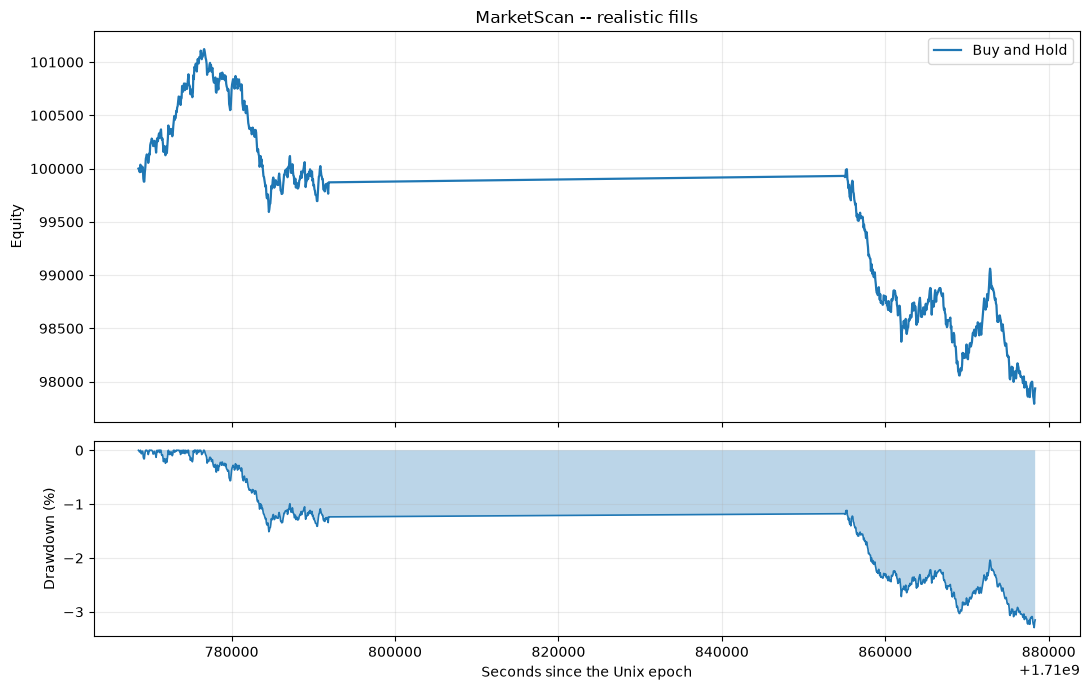

In [9]:
try:
    # No backend is forced: inside a kernel matplotlib uses the inline backend,
    # which is what puts the figure in the notebook. Selecting Agg here would
    # make plt.show() a silent no-op and the committed notebook would have a
    # plotting cell with nothing under it.
    import matplotlib.pyplot as plt
except ImportError:
    print('matplotlib not installed; skipping the charts')
else:
    fig, (top, bottom) = plt.subplots(
        2, 1, figsize=(11, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1]})

    for t in result.theories:
        top.plot(t.times, t.equity_curve, linewidth=1.6, label=t.display_name)
        underwater = [d * 100 for d in t.drawdown]
        bottom.fill_between(t.times, underwater, 0, alpha=0.3)
        bottom.plot(t.times, underwater, linewidth=1.2)

    top.set_ylabel('Equity')
    top.set_title('MarketScan -- realistic fills')
    top.legend(loc='best')
    top.grid(alpha=0.25)

    bottom.set_ylabel('Drawdown (%)')
    bottom.set_xlabel('Seconds since the Unix epoch')
    bottom.grid(alpha=0.25)

    fig.tight_layout()
    plt.show()

---

## Where to go next

- `theories/README.md` -- writing a theory. Two headers and one macro, and it
  builds without the rest of this project present.
- `marketscan.exe` -- the desktop dashboard: twelve panels, a transport with a
  scrub bar, and hot reload from the same `theories/` folder.
- `marketscan.exe --headless --compare-fills` -- the table above from the
  command line, through the same `run_backtest` this notebook calls.

Neither reference theory does anything a reasonable person would call a
strategy, and that is the point. The car is finished; the engine bay is empty
and every mount is standard.
